# ClientCo — Où se concentre le churn, signaux avant-coureurs et score à battre

**Objectif** : nouveaux clients et rétention par cohorte (Q6), concentration du churn par segment, canal et agence (Q7), signaux avant-coureurs dans les transactions seules (Q8), et le **score le plus simple** qu'un modèle devra battre (Q9). Les chiffres de ce notebook sont indicatifs (une photo, `T_SNAP`) ; les décisions de modélisation sont dans `docs/02_modeling_decisions.md`.

> **Définition du jour d'achat dans ce notebook.** Les notebooks 01 à 03 gardent la définition de l'exploration (ligne de vente strictement positive, `rev_pos`) ; à partir du notebook 04, le jour d'achat est le CA net des retours du jour > 0,01 € (décision du 24/11 : 118 009 clients au lieu de 119 656, CA de référence −6 %). Les conclusions de ces trois notebooks ne changent pas ; les décisions de périmètre et de label s'appuient sur les notebooks 04 à 08.

## 0. Setup

Le CSV fait **4,2 Go / 63 M de lignes** : impossible à charger dans pandas sur un laptop. On utilise **DuckDB** : conversion unique en Parquet (~1 min, colonnée et compressée), puis on agrège en SQL et on ne rapatrie dans pandas que de petites tables pour tracer.

In [1]:
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = next((p for p in (ROOT / "data" / "dataset_sales_2026.csv", ROOT / "dataset_sales_2026.csv") if p.exists()), ROOT / "dataset_sales_2026.csv")
PARQUET = ROOT / "data" / "sales.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
(ROOT / "data").mkdir(exist_ok=True)
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).fetchdf()


if not PARQUET.exists():
    t0 = time.time()
    con.execute(f"""
        COPY (SELECT * FROM read_csv('{CSV}', delim=';', header=true, columns={{
            'date_order':'DATE','date_invoice':'DATE','product_id':'BIGINT','client_id':'BIGINT',
            'sales_net':'DOUBLE','quantity':'DOUBLE','order_channel':'VARCHAR','branch_id':'BIGINT'}}))
        TO '{PARQUET}' (FORMAT parquet, COMPRESSION zstd)""")
    print(f"CSV -> Parquet en {time.time() - t0:.0f}s")

con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
q("SELECT * FROM sales LIMIT 5")

,date_order,date_invoice,product_id,client_id,sales_net,quantity,order_channel,branch_id
0,2022-09-25,2022-09-25,2376333,188502,155.443,3.000,online,2732
1,2022-09-25,2022-09-25,2520527,835089,16.394,3.000,at the store,10279
2,2022-09-25,2022-09-25,2536756,1977896,365.766,21.000,online,6184
3,2022-09-25,2022-09-25,3028673,598816,8.599,201.000,at the store,4200
4,2022-09-25,2022-09-25,203377,2086861,"1,093.374",3.000,by phone,7051


### Paramètres de la « photo » (modifiables)

Pour parler de churn il faut une **date d'observation T** : on regarde le passé (< T) pour décrire un client, et le futur (≥ T) pour savoir s'il est parti.
- `BASE_DAYS` : population suivie = clients ayant acheté au moins une fois dans les `BASE_DAYS` derniers jours avant T.
- `HORIZON` : un client est *churné* s'il n'achète plus pendant `HORIZON` jours après T.

Le dataset s'arrête le 22/09/2024 ; la dernière photo possible avec 180 jours d'horizon est donc le 22/03/2024. La section 4 justifie ces choix.

In [2]:
T_SNAP = "2024-03-22"   # date de la photo principale
BASE_DAYS = 180         # population = clients actifs dans les 180 derniers jours
HORIZON = 180           # churn = aucun achat pendant les 180 jours suivants
N_REPS = 200            # nombre de commerciaux (Head of Sales)

### Style graphique
Palette catégorielle validée (ordre fixe : une couleur = une entité), rampe bleue pour les magnitudes, gris neutres pour la structure, orange pour « ce qui alerte ». Fond clair pour que les figures restent lisibles quel que soit le thème de l'éditeur.

In [3]:
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)
NEUTRAL = "#b9b8b0"

# Une couleur par canal, identique dans tout le notebook
CHANNEL_COLOR = {"by phone": C["orange"], "at the store": C["blue"], "online": C["aqua"],
                 "during the visit of a sales rep": C["yellow"], "other": C["magenta"]}
CHANNEL_LABEL = {"by phone": "Téléphone", "at the store": "En agence", "online": "En ligne",
                 "during the visit of a sales rep": "Visite commercial", "other": "Autre"}

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False, "legend.fontsize": 9,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
})


def headline(fig, title, sub=None):
    """Action title (the takeaway) + optional muted subtitle, left-aligned above the figure."""
    h = fig.get_figheight()
    fig.text(0.005, 1 + (0.30 if sub else 0.12) / h, title, fontsize=13, fontweight="bold", color=INK, ha="left", va="bottom")
    if sub:
        fig.text(0.005, 1 + 0.08 / h, sub, fontsize=9.5, color=INK2, ha="left", va="bottom")


def fmt_m(x, _=None):
    return f"{x / 1e6:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    f = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def label_end(ax, x, y, text, dx=6, **kw):
    """Direct label at the end of a line (secondary ink, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(dx, 0), textcoords="offset points", va="center", color=INK2, fontsize=9, **kw)


def pct(x, d=1):
    return f"{100 * x:.{d}f} %"

### Table (client, jour d'achat)

Construite une fois à partir du Parquet (une passe sur les 63 M de lignes), comme dans `01_data_quality_and_activity_overview`.

In [8]:
# Daily client x day table (one pass over the 63M lines), then purchase days only.
t0 = time.time()
con.execute("""
CREATE OR REPLACE TABLE cd AS
SELECT client_id, date_order AS d,
       sum(sales_net)                                   AS rev_net,
       sum(greatest(sales_net, 0))                      AS rev_pos,
       sum(least(sales_net, 0))                         AS rev_neg,
       count(*)                                         AS n_lines,
       count(DISTINCT product_id)                       AS n_prod,
       arg_max(branch_id, greatest(sales_net, 0))       AS branch_id,
       arg_max(order_channel, greatest(sales_net, 0))   AS channel,
       avg(least(greatest(date_diff('day', date_order, date_invoice), 0), 365)) AS lag_mean
FROM sales GROUP BY client_id, date_order""")
con.execute("CREATE OR REPLACE TABLE bd AS SELECT * FROM cd WHERE rev_pos > 0")
cnt = q("SELECT (SELECT count(*) FROM cd) AS client_days, (SELECT count(*) FROM bd) AS purchase_days").iloc[0]
print(f"{cnt['client_days']:,.0f} (client, jour) · dont {cnt['purchase_days']:,.0f} jours d'achat · construit en {time.time() - t0:.0f}s")

7,955,289 (client, jour) · dont 7,953,336 jours d'achat · construit en 16s


In [ ]:
FREQ_BINS = [0, 5, 35, np.inf]                              # classes de fréquence (jours d'achat sur 365 j), comme dans `02_clients_rhythm_and_churn_definition`
FREQ_LABELS = ["1–5 jours d'achat / an", "6–35", "36+"]

### Table des variables à la photo `T_SNAP`

Construite une fois (variables sur 365 jours avant `T_SNAP`, futur sur `HORIZON` jours), comme dans `02_clients_rhythm_and_churn_definition`.

In [20]:
con.execute(f"""
CREATE OR REPLACE TABLE feat AS
WITH win AS (
    SELECT *, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
    FROM bd WHERE d < DATE '{T_SNAP}' AND d >= DATE '{T_SNAP}' - 365),
agg AS (
    SELECT client_id, count(*) AS f365, sum(rev_pos) AS rev365, max(d) AS last_d,
           median(gap) AS med_gap, quantile_cont(gap, 0.9) AS p90_gap,
           count(*) FILTER (WHERE d >= DATE '{T_SNAP}' - 90) AS f90,
           count(*) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180) AS f90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 90), 0) AS rev90,
           coalesce(sum(rev_pos) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180), 0) AS rev90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 180), 0) AS rev180,
           -sum(rev_neg) / nullif(sum(rev_pos), 0) AS ret_share,
           avg(lag_mean) AS lag_mean, sum(n_prod) / count(*) AS basket_breadth,
           count(DISTINCT branch_id) AS n_branch, mode(channel) AS channel, mode(branch_id) AS home_branch
    FROM win GROUP BY 1),
fut AS (
    SELECT client_id, count(*) AS n_fut, sum(rev_pos) AS rev_fut
    FROM bd WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + {HORIZON} GROUP BY 1)
SELECT a.*, date_diff('day', a.last_d, DATE '{T_SNAP}') AS recency,
       coalesce(f.n_fut, 0) AS n_fut, coalesce(f.rev_fut, 0) AS rev_fut, coalesce(f.n_fut, 0) = 0 AS churn
FROM agg a LEFT JOIN fut f USING (client_id)""")
Fall = q("SELECT * FROM feat")
F = Fall[Fall["recency"] <= BASE_DAYS].copy()
F["freq_class"] = pd.cut(F["f365"], FREQ_BINS, labels=FREQ_LABELS)
F["avg_basket"] = F["rev365"] / F["f365"]
n_base = len(F)
churn_rate = F["churn"].mean()
rev_share = (F["rev365"] * F["churn"]).sum() / F["rev365"].sum()
print(f"Photo du {T_SNAP} · base = clients actifs < {BASE_DAYS} j : {n_base:,.0f} clients · churn à {HORIZON} j = {churn_rate:.1%} des clients "
      f"= {rev_share:.1%} du CA des 12 derniers mois de la base ({(F['rev365'] * F['churn']).sum() / 1e6:,.0f} M sur {F['rev365'].sum() / 1e6:,.0f} M)")

Photo du 2024-03-22 · base = clients actifs < 180 j : 120,114 clients · churn à 180 j = 18.3% des clients = 3.1% du CA des 12 derniers mois de la base (148 M sur 4,824 M)


In [ ]:
def heat(ax, M, title, fmt="{:.0%}", vmax=None, cmap=CMAP):
    vmax = vmax if vmax is not None else np.nanmax(M.to_numpy())
    ax.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if v > vmax * 0.55 else INK)
    ax.set_xticks(range(M.shape[1]), [str(c) for c in M.columns])
    ax.set_yticks(range(M.shape[0]), [str(i) for i in M.index])
    ax.grid(False)
    ax.set_title(title)
    for sp in ax.spines.values():
        sp.set_visible(False)

## 1. Les nouveaux clients restent-ils ? (cohortes)

**Question Q6.** Le jeu de données démarre au 22/09/2022 : tous les clients déjà existants apparaissent « nouveaux » en septembre-octobre 2022 (*left-censoring*). Pour identifier de vrais nouveaux clients, on impose une **période de chauffe de 3 mois** (premier achat à partir du 22/12/2022) : le 99e percentile des écarts d'achat est de ~4 mois, quelques « nouveaux » sont donc en réalité des clients dormants qui reviennent.

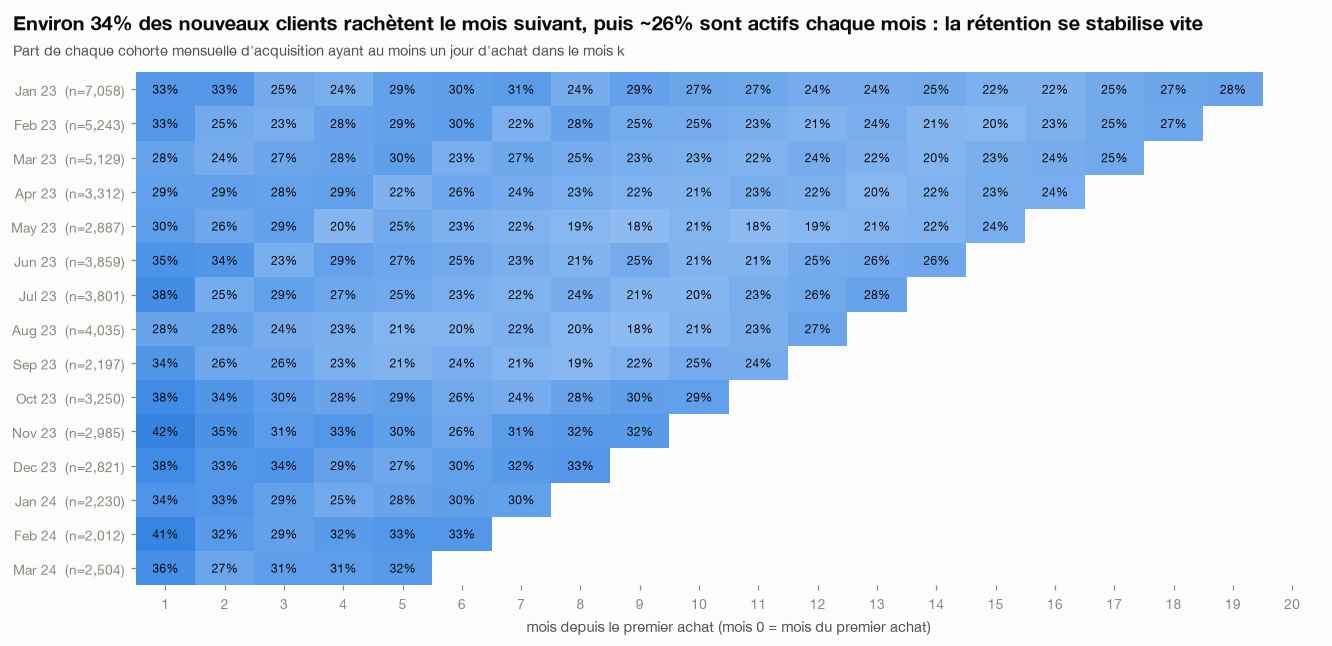

In [26]:
coh = q("""
WITH f AS (SELECT client_id, min(d) AS first_d FROM bd GROUP BY 1),
c AS (SELECT client_id, date_trunc('month', first_d) AS coh FROM f WHERE first_d >= DATE '2023-01-01' AND first_d < DATE '2024-04-01'),
act AS (SELECT DISTINCT client_id, date_trunc('month', d) AS m FROM bd)
SELECT c.coh, date_diff('month', c.coh, act.m) AS k, count(*) AS n FROM c JOIN act USING (client_id) GROUP BY 1, 2""")
mat = coh.pivot(index="coh", columns="k", values="n")
ret = mat.div(mat[0], axis=0)
last_full = pd.Timestamp("2024-08-01")
for coh_date in ret.index:
    for k in ret.columns:
        if coh_date + pd.DateOffset(months=int(k)) > last_full:
            ret.loc[coh_date, k] = np.nan
ret = ret.iloc[:, 1:]  # k=0 is 100 % by construction
ret.index = [d.strftime("%b %y") for d in ret.index]
n0 = mat[0].to_numpy()

fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
M = ret.to_numpy()
ax.imshow(np.ma.masked_invalid(M), cmap=CMAP, vmin=0, vmax=0.8, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.45 else INK)
ax.set_xticks(range(M.shape[1]), [str(c) for c in ret.columns])
ax.set_yticks(range(M.shape[0]), [f"{i}  (n={n_:,.0f})" for i, n_ in zip(ret.index, n0)])
ax.set_xlabel("mois depuis le premier achat (mois 0 = mois du premier achat)")
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
m1 = np.nanmean(ret[1]); m6 = np.nanmean(ret[6]); m12 = np.nanmean(ret[12]) if 12 in ret.columns else np.nan
headline(fig, f"Environ {m1:.0%} des nouveaux clients rachètent le mois suivant, puis ~{m6:.0%} sont actifs chaque mois : la rétention se stabilise vite",
         "Part de chaque cohorte mensuelle d'acquisition ayant au moins un jour d'achat dans le mois k")
plt.show()

Seul **un tiers** des nouveaux clients rachète le mois suivant, puis environ **un quart** est actif chaque mois, de façon plate (les nouveaux clients sont surtout des acheteurs occasionnels). Les cohortes sont **homogènes** d'un mois à l'autre (pas de dégradation récente). Le début de relation est la phase la plus incertaine, mais aussi celle où la **donnée est la plus pauvre** (1 ou 2 achats) : le modèle de churn sera moins précis sur cette population.

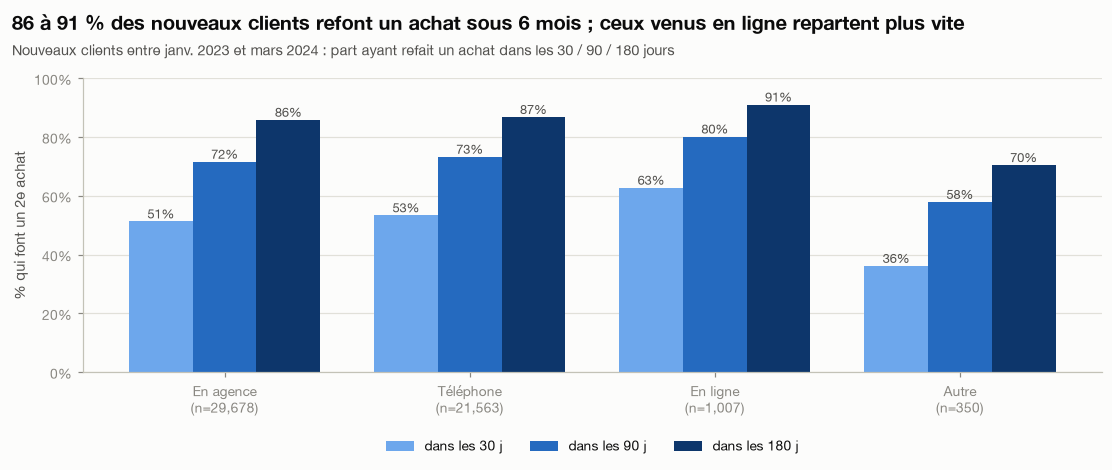

In [27]:
sec = q("""
WITH r AS (SELECT client_id, d, channel, row_number() OVER (PARTITION BY client_id ORDER BY d) AS rn FROM bd),
f AS (SELECT client_id, d AS first_d, channel FROM r WHERE rn = 1 AND d >= DATE '2023-01-01' AND d < DATE '2024-03-22'),
s AS (SELECT client_id, d AS second_d FROM r WHERE rn = 2)
SELECT f.channel, count(*) AS n,
       avg((date_diff('day', first_d, second_d) <= 30)::int) AS r30,
       avg((date_diff('day', first_d, second_d) <= 90)::int) AS r90,
       avg((date_diff('day', first_d, second_d) <= 180)::int) AS r180
FROM f LEFT JOIN s USING (client_id) GROUP BY 1""").set_index("channel")
sec = sec[sec["n"] >= 300].sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
x = np.arange(len(sec))
w = 0.26
for off, col, colr, lab in [(-w, "r30", SEQ[2], "dans les 30 j"), (0, "r90", SEQ[4], "dans les 90 j"), (w, "r180", SEQ[6], "dans les 180 j")]:
    ax.bar(x + off, sec[col], width=w, color=colr, label=lab)
    for xi, v in zip(x + off, sec[col]):
        ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, [f"{CHANNEL_LABEL[c]}\n(n={n_:,.0f})" for c, n_ in zip(sec.index, sec["n"])])
pct_axis(ax)
ax.set_ylim(0, 1)
ax.set_ylabel("% qui font un 2e achat")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
headline(fig, "86 à 91 % des nouveaux clients refont un achat sous 6 mois ; ceux venus en ligne repartent plus vite",
         "Nouveaux clients entre janv. 2023 et mars 2024 : part ayant refait un achat dans les 30 / 90 / 180 jours")
plt.show()

## 2. Où se concentre le churn ?

**Question Q7.** Avec la photo principale (`T_SNAP`), on découpe le taux de churn par les dimensions disponibles. Attention aux **effets de confusion** : fréquence, récence et valeur sont liées entre elles ; on isole donc les clients réguliers quand c'est pertinent.

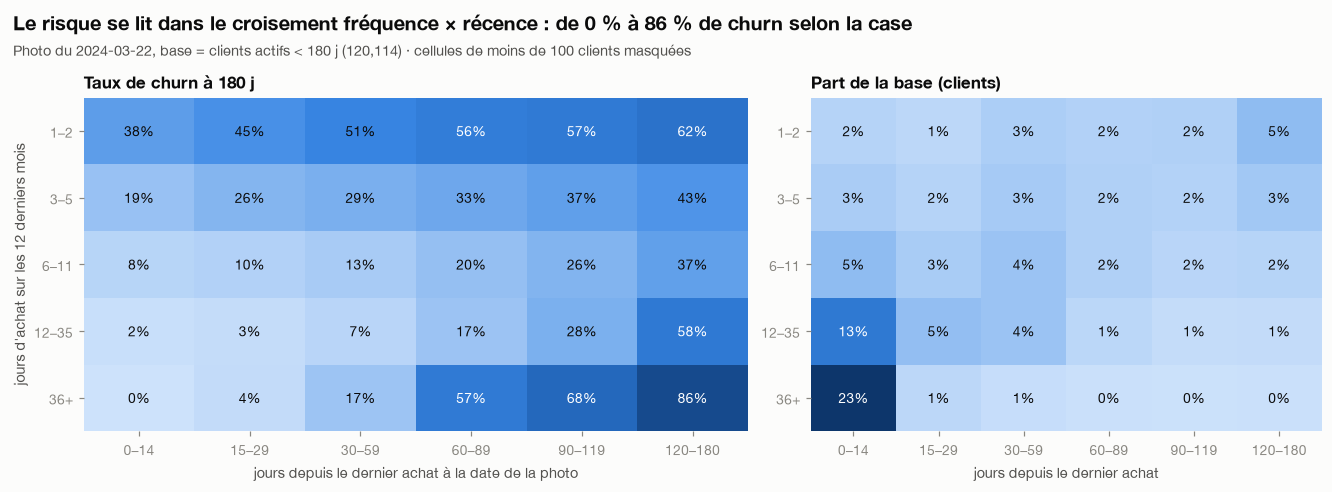

In [28]:
F["freq5"] = pd.cut(F["f365"], [0, 2, 5, 11, 35, np.inf], labels=["1–2", "3–5", "6–11", "12–35", "36+"])
F["rec_bin"] = pd.cut(F["recency"], [-1, 14, 29, 59, 89, 119, 180], labels=["0–14", "15–29", "30–59", "60–89", "90–119", "120–180"])
hm = F.pivot_table(index="freq5", columns="rec_bin", values="churn", aggfunc="mean", observed=False)
hn = F.pivot_table(index="freq5", columns="rec_bin", values="churn", aggfunc="count", observed=False)
hm = hm.where(hn >= 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1]})
heat(axes[0], hm, "Taux de churn à 180 j", vmax=1.0)
axes[0].set_xlabel("jours depuis le dernier achat à la date de la photo")
axes[0].set_ylabel("jours d'achat sur les 12 derniers mois")
hn_pct = hn / hn.to_numpy().sum()
heat(axes[1], hn_pct, "Part de la base (clients)", vmax=hn_pct.to_numpy().max())
axes[1].set_xlabel("jours depuis le dernier achat")
headline(fig, "Le risque se lit dans le croisement fréquence × récence : de 0 % à 86 % de churn selon la case",
         f"Photo du {T_SNAP}, base = clients actifs < {BASE_DAYS} j ({n_base:,.0f}) · cellules de moins de 100 clients masquées")
plt.show()

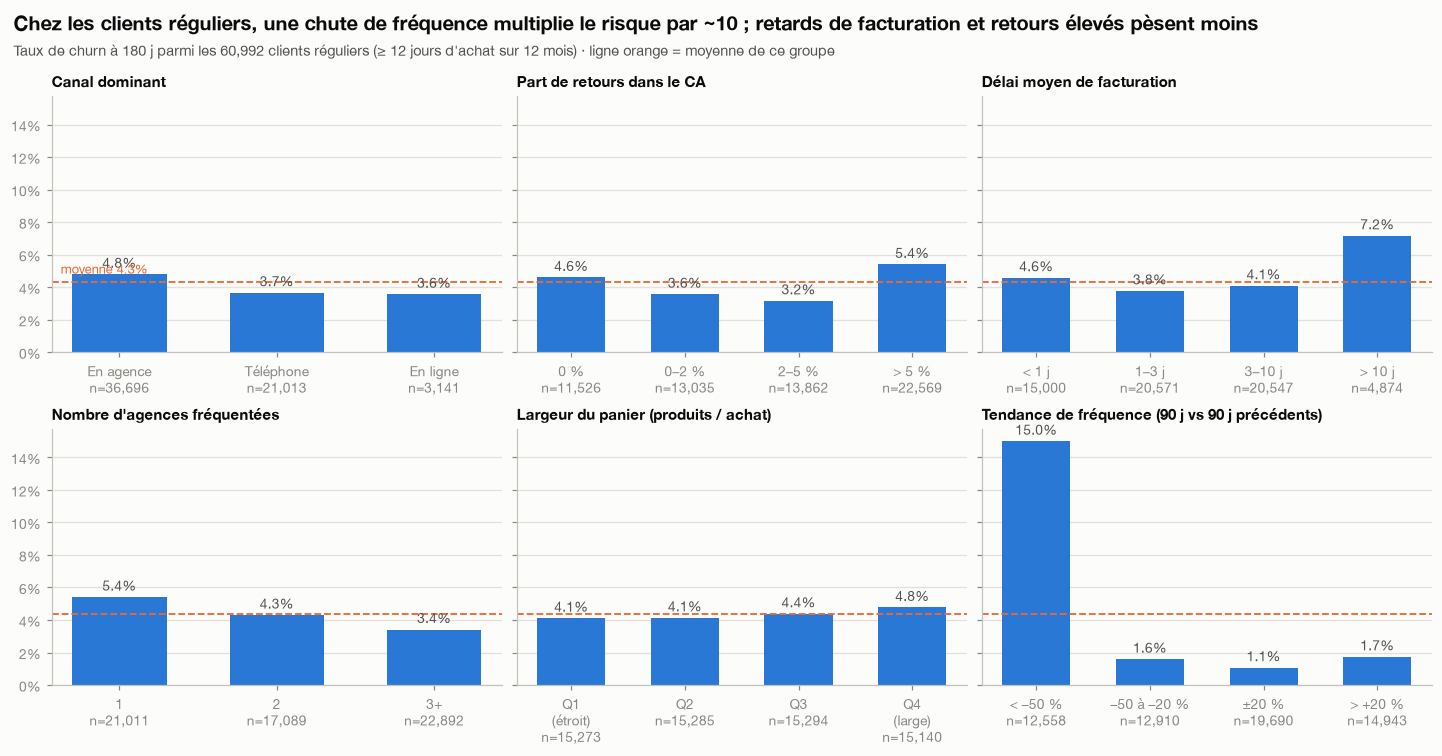

In [29]:
R = F[F["f365"] >= 12].copy()  # regular clients: where retention effort is worth it
R["ret_bin"] = pd.cut(R["ret_share"].fillna(0), [-1, 0, 0.02, 0.05, np.inf], labels=["0 %", "0–2 %", "2–5 %", "> 5 %"])
R["lag_bin"] = pd.cut(R["lag_mean"], [-1, 1, 3, 10, np.inf], labels=["< 1 j", "1–3 j", "3–10 j", "> 10 j"])
R["br_bin"] = pd.cut(R["n_branch"], [0, 1, 2, np.inf], labels=["1", "2", "3+"])
R["breadth_bin"] = pd.qcut(R["basket_breadth"], 4, labels=["Q1\n(étroit)", "Q2", "Q3", "Q4\n(large)"])
ratio = R["f90"] / R["f90_prev"].replace(0, np.nan)
R["trend_bin"] = pd.cut(ratio, [-1, 0.5, 0.8, 1.2, np.inf], labels=["< –50 %", "–50 à –20 %", "±20 %", "> +20 %"])
R["chan_bin"] = R["channel"].map(CHANNEL_LABEL)

panels = [("Canal dominant", "chan_bin", ["En agence", "Téléphone", "En ligne"]),
          ("Part de retours dans le CA", "ret_bin", None), ("Délai moyen de facturation", "lag_bin", None),
          ("Nombre d'agences fréquentées", "br_bin", None), ("Largeur du panier (produits / achat)", "breadth_bin", None),
          ("Tendance de fréquence (90 j vs 90 j précédents)", "trend_bin", None)]
base_rate = R["churn"].mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), constrained_layout=True, sharey=True)
for ax, (ttl, col, keep) in zip(axes.flat, panels):
    g_ = R.groupby(col, observed=True)["churn"].agg(["mean", "count"])
    if keep:
        g_ = g_.loc[[k for k in keep if k in g_.index]]
    g_ = g_[g_["count"] >= 100]
    ax.bar(range(len(g_)), g_["mean"], width=0.6, color=C["blue"])
    for i, (m_, n_) in enumerate(zip(g_["mean"], g_["count"])):
        ax.text(i, m_ + 0.004, f"{m_:.1%}", ha="center", fontsize=9, color=INK2)
    ax.axhline(base_rate, color=C["orange"], lw=1.2, ls="--")
    ax.set_xticks(range(len(g_)), [f"{i}\nn={n_:,.0f}" for i, n_ in zip(g_.index, g_["count"])])
    ax.set_title(ttl, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    pct_axis(ax)
axes[0, 0].text(0.02, base_rate + 0.003, f"moyenne {base_rate:.1%}", transform=axes[0, 0].get_yaxis_transform(), ha="left", fontsize=8.5, color=C["orange"], va="bottom")
headline(fig, "Chez les clients réguliers, une chute de fréquence multiplie le risque par ~10 ; retards de facturation et retours élevés pèsent moins",
         f"Taux de churn à {HORIZON} j parmi les {len(R):,.0f} clients réguliers (≥ 12 jours d'achat sur 12 mois) · ligne orange = moyenne de ce groupe")
plt.show()

**Lecture** (vues univariées, partiellement confondues entre elles) :
- La **chute de fréquence** est de loin le signal le plus fort : un client régulier dont la fréquence a **plus que divisé par 2** sur les 90 derniers jours a **~15 % de risque de départ, contre ~1-2 % ailleurs** (×10). Attention : ce signal est en partie *mécanique* (le groupe « < –50 % » inclut les clients déjà silencieux depuis 90 jours), c'est précisément l'alerte précoce recherchée.
- Un **délai moyen de facturation > 10 jours** (7,2 % vs 4,3 %) et une **part de retours > 5 %** (5,4 %) sont associés à plus de churn : cohérent avec l'hypothèse de la Supply Chain (« délais et ruptures font partir les clients »), mais l'effet reste **secondaire** (×1,3 à ×1,7) et le proxy est imparfait ; il faudra les données de stock / livraison pour le confirmer (UC n°2).
- Les clients **mono-agence** (5,4 %) et en **agence** (4,8 %) churnent un peu plus que les multi-agences (3,4 %) et le téléphone / en ligne (~3,5 %) : l'ancrage multi-points de vente est protecteur.
- La **largeur du panier** n'est pas discriminante.

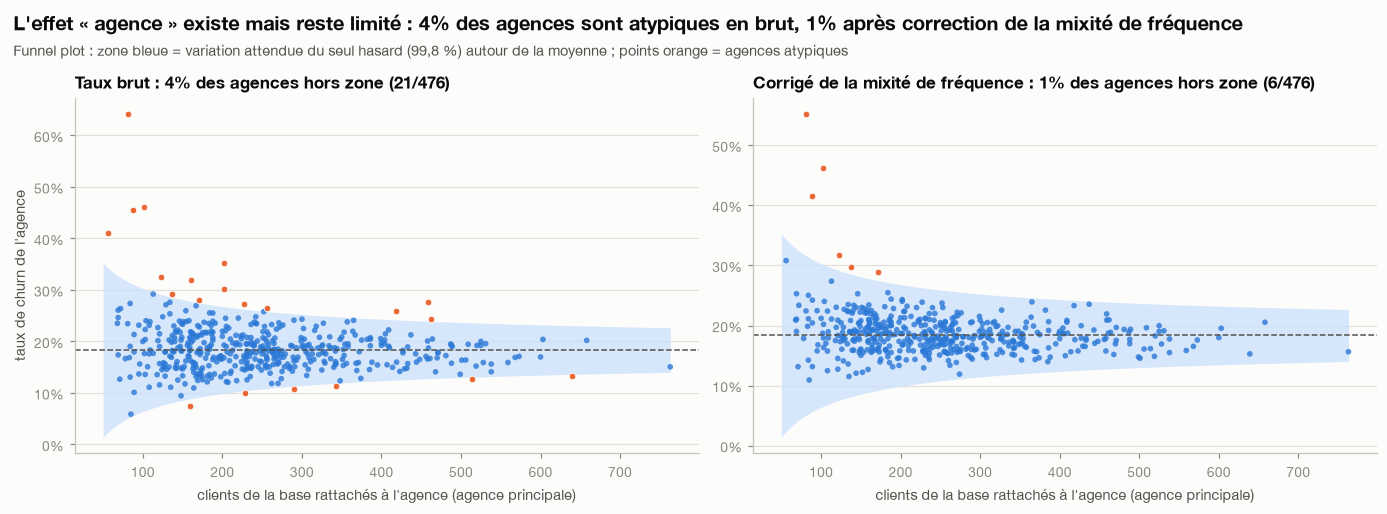

,n,churn,exp,z_adj
home_branch,,,,
10816,81,0.642,0.273,7.450
3627,102,0.461,0.182,7.284
1858,88,0.455,0.222,5.251
3679,123,0.325,0.190,3.806
10126,171,0.281,0.175,3.639


In [30]:
MIN_CL = 50
bt = F.groupby("home_branch").agg(n=("churn", "size"), churn=("churn", "mean"))
# expected churn if the branch had the same frequency mix as the base (indirect standardisation)
class_rate = F.groupby("freq5", observed=True)["churn"].mean()
F["exp"] = F["freq5"].map(class_rate).astype(float)
bt["exp"] = F.groupby("home_branch")["exp"].mean()
bt = bt[bt["n"] >= MIN_CL]
p0 = F["churn"].mean()
nn = np.linspace(MIN_CL, bt["n"].max(), 200)
lim95, lim998 = 1.96 * np.sqrt(p0 * (1 - p0) / nn), 3.09 * np.sqrt(p0 * (1 - p0) / nn)
bt["z_raw"] = (bt["churn"] - p0) / np.sqrt(p0 * (1 - p0) / bt["n"])
bt["z_adj"] = (bt["churn"] - bt["exp"]) / np.sqrt(bt["exp"] * (1 - bt["exp"]) / bt["n"])
out_raw, out_adj = (bt["z_raw"].abs() > 3.09).mean(), (bt["z_adj"].abs() > 3.09).mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), constrained_layout=True)
for ax, ycol, center, ttl, zcol in [(axes[0], bt["churn"], p0, "Taux brut", "z_raw"), (axes[1], bt["churn"] - bt["exp"] + p0, p0, "Corrigé de la mixité de fréquence", "z_adj")]:
    out = bt[zcol].abs() > 3.09
    ax.fill_between(nn, center - lim998, center + lim998, color=SEQ[0], alpha=0.8, lw=0)
    ax.scatter(bt.loc[~out, "n"], ycol[~out], s=14, color=C["blue"], alpha=0.8, edgecolors="none")
    ax.scatter(bt.loc[out, "n"], ycol[out], s=18, color=C["orange"], edgecolors=SURF, linewidths=0.5)
    ax.axhline(center, color=INK2, lw=1, ls="--")
    pct_axis(ax)
    ax.set_xlabel("clients de la base rattachés à l'agence (agence principale)")
    ax.set_title(f"{ttl} : {out.mean():.0%} des agences hors zone ({out.sum()}/{len(bt)})")
axes[0].set_ylabel("taux de churn de l'agence")
headline(fig, f"L'effet « agence » existe mais reste limité : {out_raw:.0%} des agences sont atypiques en brut, {out_adj:.0%} après correction de la mixité de fréquence",
         "Funnel plot : zone bleue = variation attendue du seul hasard (99,8 %) autour de la moyenne ; points orange = agences atypiques")
plt.show()
bt.sort_values("z_adj", ascending=False)[["n", "churn", "exp", "z_adj"]].head(5)

**Lecture** : en brut, ~4 % des agences sortent de l'intervalle attendu (le hasard n'en expliquerait que ~0,2 %) ; une fois la **mixité de fréquence** des clients prise en compte, il n'en reste que **~1 %** (une demi-douzaine d'agences, de petite taille, avec 30 à 65 % de churn). L'effet agence est donc **réel mais faible** : l'essentiel de la variation entre agences vient de la composition de leur clientèle. Ces quelques agences atypiques sont néanmoins de bons candidats pour le pilote (ou à investiguer côté ruptures / concurrence locale). Attention à l'attribution client → agence (notebook `02_clients_rhythm_and_churn_definition`, section 1 : près de la moitié des clients sont multi-agences).

## 3. Signaux avant-coureurs dans les transactions

**Question Q8.** Le Sales Manager craint que « la data soit trop réductrice » ; la Data team rappelle qu'il n'y a que des transactions. Quels signaux ces transactions contiennent-elles *avant* le départ ? On compare, sur les 12 mois précédant la photo, les clients **actifs récemment** (< 90 j) et **réguliers** (≥ 6 jours d'achat) qui partiront ou resteront.

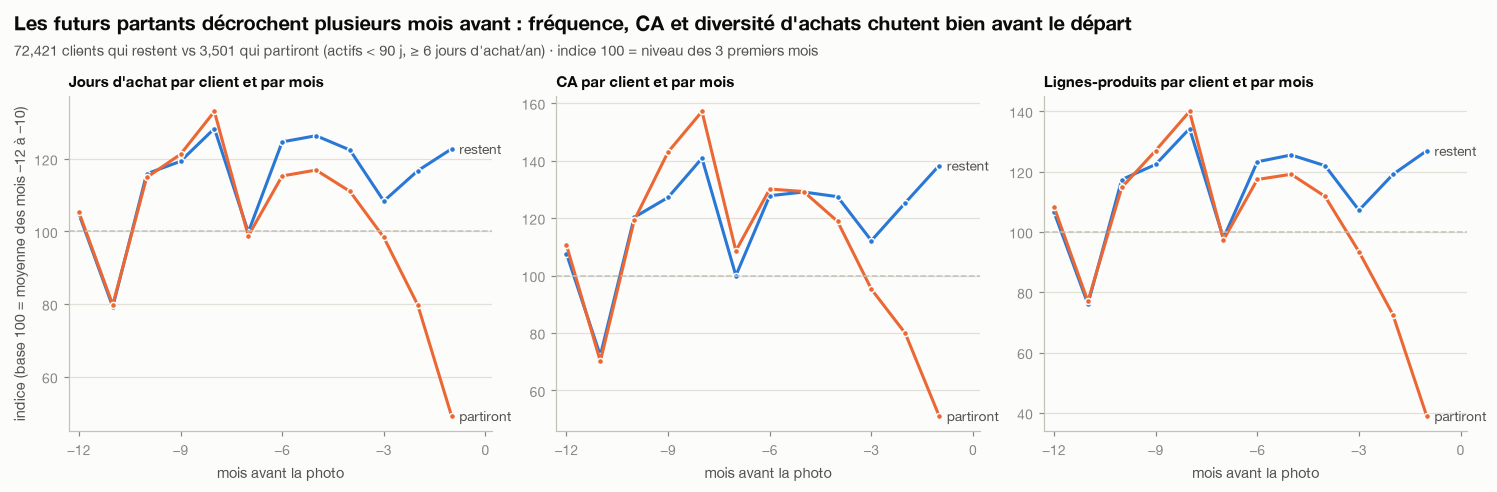

In [31]:
traj = q(f"""
SELECT f.churn, floor((date_diff('day', b.d, DATE '{T_SNAP}') - 1) / 30)::int AS bk,
       count(*) AS pdays, sum(b.rev_pos) AS rev, sum(b.n_prod) AS prods
FROM bd b JOIN feat f USING (client_id)
WHERE b.d < DATE '{T_SNAP}' AND b.d >= DATE '{T_SNAP}' - 360 AND f.recency <= 90 AND f.f365 >= 6
GROUP BY 1, 2""")
ng = q("SELECT churn, count(*) AS n FROM feat WHERE recency <= 90 AND f365 >= 6 GROUP BY 1").set_index("churn")["n"]
traj["months_before"] = -(traj["bk"] + 1)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), constrained_layout=True, sharex=True)
for ax, col, ttl in zip(axes, ["pdays", "rev", "prods"], ["Jours d'achat par client et par mois", "CA par client et par mois", "Lignes-produits par client et par mois"]):
    for churn_flag, colr, lab in [(False, C["blue"], "restent"), (True, C["orange"], "partiront")]:
        d = traj[traj["churn"] == churn_flag].sort_values("months_before")
        v = d[col] / ng[churn_flag]
        ref = v[d["months_before"] <= -10].mean()
        ax.plot(d["months_before"], 100 * v / ref, color=colr, marker="o", ms=4, mec=SURF, mew=1)
        label_end(ax, d["months_before"].iloc[-1], 100 * v.iloc[-1] / ref, lab, dx=5)
    ax.axhline(100, color=AXIS, lw=1, ls="--")
    ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("mois avant la photo")
    ax.set_xlim(-12.3, 0.2)
    ax.set_xticks(range(-12, 1, 3))
axes[0].set_ylabel("indice (base 100 = moyenne des mois –12 à –10)")
n_f, n_r = ng[True], ng[False]
headline(fig, "Les futurs partants décrochent plusieurs mois avant : fréquence, CA et diversité d'achats chutent bien avant le départ",
         f"{n_r:,.0f} clients qui restent vs {n_f:,.0f} qui partiront (actifs < 90 j, ≥ 6 jours d'achat/an) · indice 100 = niveau des 3 premiers mois")
plt.show()

Les clients qui partiront **achètent moins souvent, moins cher et moins varié** dès ~5 mois avant la photo, avec une chute franche sur les 3 derniers mois, alors que ceux qui restent sont stables (les creux communs aux deux courbes aux mois –11 et –7 sont les creux saisonniers de mai et septembre 2023). Une partie du décrochage du dernier mois est mécanique (par définition, ces clients n'achètent plus ensuite), mais la **baisse débute bien avant** : un signal d'**alerte précoce** présent dans les transactions seules — contrairement à l'idée que le départ serait « imprévisible ».

### Pouvoir prédictif de chaque variable prise isolément
Un AUC (aire sous la courbe ROC) de 0,5 = aucune information, 1,0 = séparation parfaite. Ce n'est **pas un modèle** mais un classement des pistes de features, avant d'en tirer un vrai.

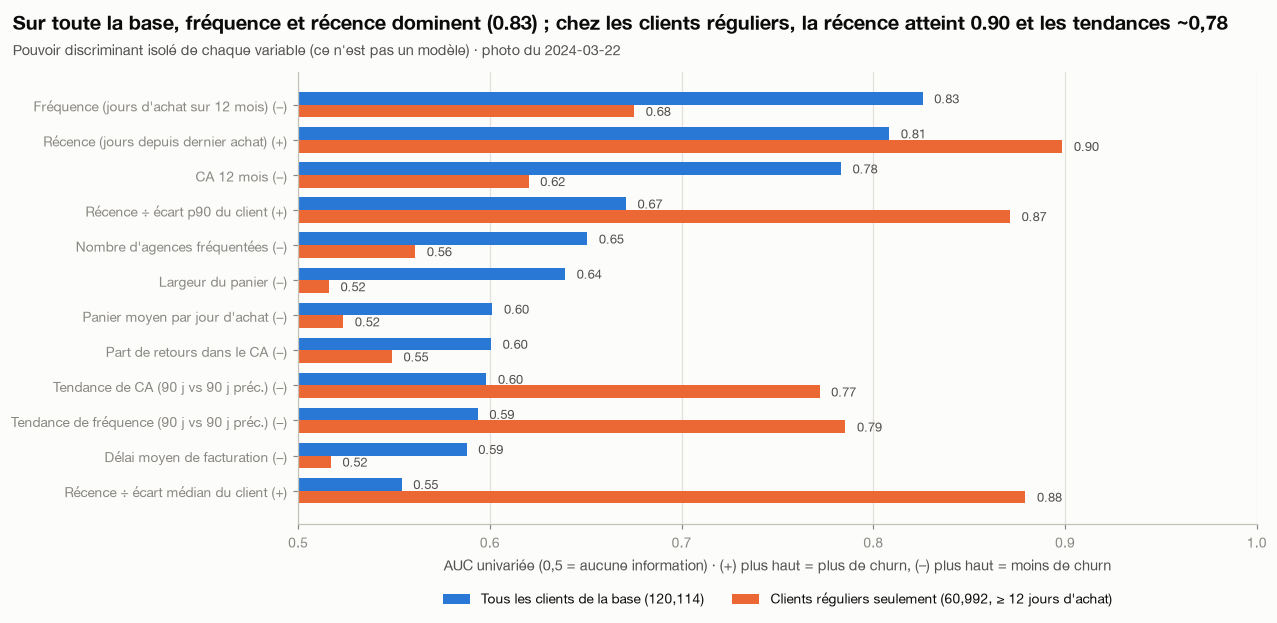

,tous,reguliers
Récence (jours depuis dernier achat),0.808,0.899
Récence ÷ écart médian du client,0.554,0.879
Récence ÷ écart p90 du client,0.671,0.871
Tendance de fréquence (90 j vs 90 j préc.),0.594,0.785
Tendance de CA (90 j vs 90 j préc.),0.598,0.772
Fréquence (jours d'achat sur 12 mois),0.826,0.675
CA 12 mois,0.783,0.620
Nombre d'agences fréquentées,0.651,0.561
Part de retours dans le CA,0.601,0.549
Panier moyen par jour d'achat,0.601,0.524


In [32]:
X = pd.DataFrame(index=F.index)
mg = F["med_gap"].fillna(180).clip(lower=1)
p90 = F["p90_gap"].fillna(180).clip(lower=1)
X["Récence (jours depuis dernier achat)"] = F["recency"]
X["Récence ÷ écart médian du client"] = F["recency"] / mg
X["Récence ÷ écart p90 du client"] = F["recency"] / p90
X["Fréquence (jours d'achat sur 12 mois)"] = F["f365"]
X["CA 12 mois"] = F["rev365"]
X["Panier moyen par jour d'achat"] = F["avg_basket"]
X["Tendance de fréquence (90 j vs 90 j préc.)"] = (F["f90"] - F["f90_prev"]) / (F["f90"] + F["f90_prev"]).replace(0, np.nan)
X["Tendance de CA (90 j vs 90 j préc.)"] = (F["rev90"] - F["rev90_prev"]) / (F["rev90"] + F["rev90_prev"]).replace(0, np.nan)
X["Part de retours dans le CA"] = F["ret_share"].fillna(0)
X["Délai moyen de facturation"] = F["lag_mean"]
X["Largeur du panier"] = F["basket_breadth"]
X["Nombre d'agences fréquentées"] = F["n_branch"]
X = X.fillna(X.median())


def auc(y, sc):
    r = pd.Series(sc, index=y.index).rank()
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


y_ = F["churn"].astype(int)
reg = F["f365"] >= 12
au_all = pd.Series({c: auc(y_, X[c]) for c in X.columns})
au_reg = pd.Series({c: auc(y_[reg], X.loc[reg, c]) for c in X.columns})
res = pd.DataFrame({"tous": (au_all - 0.5).abs() + 0.5, "reguliers": (au_reg - 0.5).abs() + 0.5, "plus_haut_egal_plus_de_churn": au_all >= 0.5}).sort_values("tous")

fig, ax = plt.subplots(figsize=(11.5, 5), constrained_layout=True)
yy = np.arange(len(res))
h = 0.36
ax.barh(yy + h / 2, res["tous"] - 0.5, left=0.5, height=h, color=C["blue"], label=f"Tous les clients de la base ({n_base:,.0f})")
ax.barh(yy - h / 2, res["reguliers"] - 0.5, left=0.5, height=h, color=C["orange"], label=f"Clients réguliers seulement ({int(reg.sum()):,.0f}, ≥ 12 jours d'achat)")
for yi, a_, r_ in zip(yy, res["tous"], res["reguliers"]):
    ax.text(a_ + 0.006, yi + h / 2, f"{a_:.2f}", va="center", fontsize=8.5, color=INK2)
    ax.text(r_ + 0.006, yi - h / 2, f"{r_:.2f}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(yy, [f"{n_} ({'+' if sgn else '–'})" for n_, sgn in zip(res.index, res["plus_haut_egal_plus_de_churn"])])
ax.axvline(0.5, color=INK2, lw=1)
ax.set_xlim(0.5, 1.0)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC univariée (0,5 = aucune information) · (+) plus haut = plus de churn, (–) plus haut = moins de churn")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
headline(fig, f"Sur toute la base, fréquence et récence dominent ({res['tous'].max():.2f}) ; chez les clients réguliers, la récence atteint {res['reguliers'].max():.2f} et les tendances ~0,78",
         f"Pouvoir discriminant isolé de chaque variable (ce n'est pas un modèle) · photo du {T_SNAP}")
plt.show()
res[["tous", "reguliers"]].sort_values("reguliers", ascending=False)

**Lecture** — à ne pas surinterpréter (AUC univarié, pas de modèle) :
- Sur **toute la base**, ce sont la **fréquence**, la **récence** et le **CA** qui dominent. Ils mesurent surtout la **taille / régularité** du client : les petits clients occasionnels partent plus, ce qui est facile à prédire mais **peu intéressant commercialement**.
- La **récence rapportée à l'écart médian du client** est un cas d'école : AUC **0,88** chez les clients réguliers, mais seulement **0,55** sur toute la base. Pour un client occasionnel (peu d'achats) le rythme n'est pas estimable (valeur imputée, écarts instables) et le ratio n'a aucun sens. À retenir pour le feature engineering : les variables de rythme doivent être **calculées seulement quand l'historique le permet** (≥ 6 achats) et combinées à la fréquence ; un modèle à arbres gère cela naturellement.
- Même chez les réguliers, la **récence brute** reste la meilleure variable en AUC (0,90) : les variables relatives n'apportent leur valeur que lorsqu'on pondère par le **CA** (cf. section 4).
- Les **retours, le délai de facturation et la largeur de panier** discriminent peu (AUC 0,52-0,60) ; la **tendance de fréquence / de CA** devient utile chez les clients réguliers (AUC ~0,78).
- Un modèle multivarié (gradient boosting par exemple) combinera ces signaux ; il sera à évaluer **par segment de fréquence et en valeur**, pas seulement en AUC global.

## 4. Quelle liste d'action est réaliste ? Le « score à battre »

**Question Q9.** ~200 commerciaux, une visite coûte ~4 h (3 h + 1 h de suivi), le téléphone est « le meilleur » canal. Une liste de clients à rappeler doit donc être **courte et précise**. On teste le **score le plus simple possible** (une seule variable), qu'un modèle devra clairement battre pour justifier sa complexité.

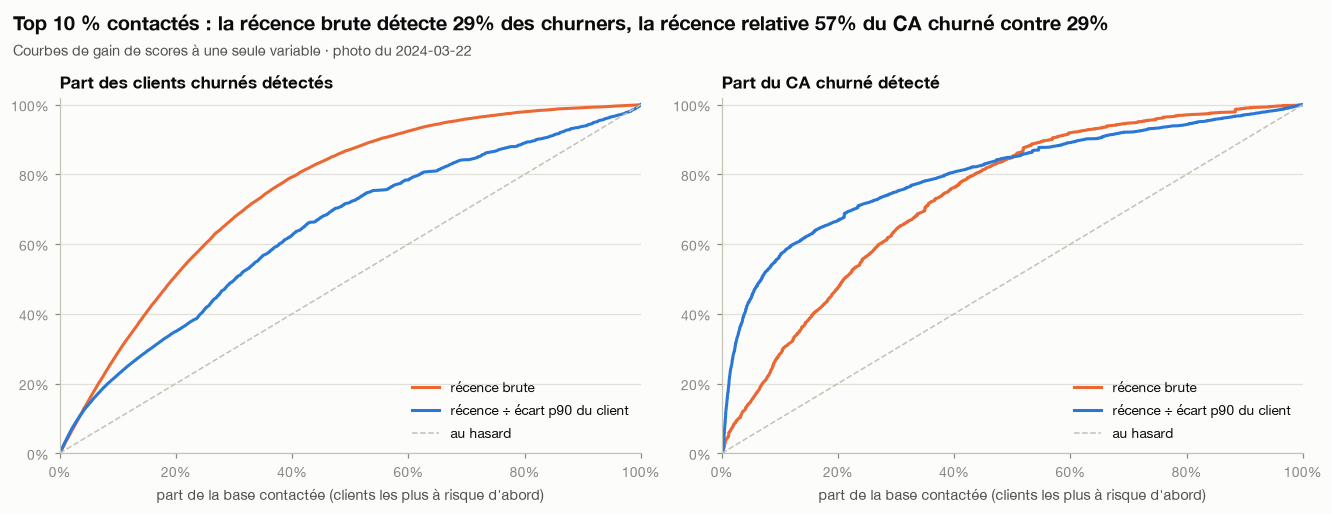

part_de_la_base precision churners_detectes ca_churn_detecte clients_par_commercial heures_par_commercial_si_visites
score                         taille_liste                                                                                                                     
récence brute                 2000                      2%       57%                5%               7%                     10                               40
                              5000                      4%       56%               13%              13%                     25                              100
                              10000                     8%       54%               24%              23%                     50                              200
                              20000                    17%       49%               44%              41%                    100                              400
récence ÷ écart p90 du client 2000                      2%       62%                6%              25%                     10                               40
                              5000                      4%       54%               12%              41%                     25                              100
                              10000                     8%       44%               20%              53%                     50                              200
                              20000                    17%       34%               31%              64%                    100                              400

In [33]:
sc = pd.DataFrame({"churn": F["churn"].to_numpy(), "rev": F["rev365"].to_numpy(), "recency": F["recency"].to_numpy(),
                   "rel90": (F["recency"] / p90).to_numpy(), "rel50": (F["recency"] / mg).to_numpy()})
SCORES = [("recency", C["orange"], "récence brute"), ("rel90", C["blue"], "récence ÷ écart p90 du client")]


def gain(df, score_col):
    d = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    x_ = (np.arange(len(d)) + 1) / len(d)
    return x_, d["churn"].cumsum() / d["churn"].sum(), (d["rev"] * d["churn"]).cumsum() / (d["rev"] * d["churn"]).sum()


fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, k, ttl in [(axes[0], 1, "Part des clients churnés détectés"), (axes[1], 2, "Part du CA churné détecté")]:
    for col, colr, lab in SCORES:
        out = gain(sc, col)
        ax.plot(out[0], out[k], color=colr, label=lab)
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--", label="au hasard")
    pct_axis(ax)
    pct_axis(ax, "x")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("part de la base contactée (clients les plus à risque d'abord)")
    ax.set_title(ttl)
    ax.legend(loc="lower right")
i10 = int(0.1 * len(sc))
g_rec, g_rel = gain(sc, "recency"), gain(sc, "rel90")
headline(fig, f"Top 10 % contactés : la récence brute détecte {g_rec[1][i10]:.0%} des churners, la récence relative {g_rel[2][i10]:.0%} du CA churné contre {g_rec[2][i10]:.0%}",
         f"Courbes de gain de scores à une seule variable · photo du {T_SNAP}")
plt.show()

rows = []
for col, _, lab in SCORES:
    d = sc.sort_values(col, ascending=False).reset_index(drop=True)
    for N in (2000, 5000, 10000, 20000):
        top_ = d.head(N)
        rows.append(dict(score=lab, taille_liste=N, part_de_la_base=N / len(d), precision=top_["churn"].mean(),
                         churners_detectes=top_["churn"].sum() / d["churn"].sum(),
                         ca_churn_detecte=(top_["rev"] * top_["churn"]).sum() / (d["rev"] * d["churn"]).sum(),
                         clients_par_commercial=N / N_REPS, heures_par_commercial_si_visites=N / N_REPS * 4))
tbl = pd.DataFrame(rows).set_index(["score", "taille_liste"])
for c_ in ["part_de_la_base", "precision", "churners_detectes", "ca_churn_detecte"]:
    tbl[c_] = tbl[c_].map("{:.0%}".format)
tbl["clients_par_commercial"] = tbl["clients_par_commercial"].map("{:.0f}".format)
tbl["heures_par_commercial_si_visites"] = tbl["heures_par_commercial_si_visites"].map("{:.0f}".format)
tbl

**Lecture** : les deux scores simples racontent des histoires **différentes** selon la métrique.
- En **nombre de clients**, la récence brute capte davantage de churners (elle repère les petits clients qui s'éloignent).
- En **valeur**, la récence **rapportée au rythme du client** est bien meilleure : elle repère les gros clients réguliers en rupture de rythme, c'est-à-dire ceux qui valent la peine d'être appelés.
- Le tableau chiffre le compromis **taille de liste ↔ précision ↔ capacité commerciale**. Hypothèse de capacité retenue (25/11) : 500 appels par semaine pour l'entreprise, soit K ≈ 700 par liste mensuelle à l'échelle du dataset (≈ 30 % du CA) ; les K plus grands de ce tableau servent de sensibilité (en visite, à ~4 h par client, la charge devient vite lourde).

Un modèle devra donc apporter : (1) une **priorisation par valeur espérée** (probabilité de départ × CA) plutôt que par probabilité seule, (2) une alerte **plus précoce** que le simple silence, (3) une **précision** suffisante pour que les commerciaux — sceptiques et peu adeptes du CRM — jugent la liste crédible dès le premier mois.